## **2 Supervised Text Classification**

---

### **2.1 Build the Model**

---

#### **2.1.1 Import Libraries**


In [1]:
%matplotlib inline

import re
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report, roc_auc_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

SEED = 42                         # Fix the random seed to facilitate experiment reproducibility.
LABELS = ["benign", "jailbreak"]  # Fix the order of categories in the assessment report.
SAVE_PLOTS = False                # To save the image separately, change this value to True.

#### **2.1.2 Load the Train and Test Sets**

There are 3,500 training prompts and 1,500 test prompts.

In [2]:
data_dir = Path("DATASET/splits")

if not data_dir.is_dir():
    data_dir = Path("PART_B/DATASET/splits")
if not data_dir.is_dir():
    data_dir = Path("TXSA/PART_B/DATASET/splits")

train_df = pd.read_csv(data_dir / "train.csv", keep_default_na=False)
test_df = pd.read_csv(data_dir / "test.csv", keep_default_na=False)

# Check the data size and the number of categories in both files.
print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nTest labels:")
print(test_df["label"].value_counts())

Training set shape: (3500, 2)
Test set shape: (1500, 2)

Training labels:
label
benign       2101
jailbreak    1399
Name: count, dtype: int64

Test labels:
label
benign       900
jailbreak    600
Name: count, dtype: int64


#### **2.1.3 Clean the Text**

The cleaning step removes extra spaces and keeps internal line breaks. The word tokenizer treats line breaks as separators. TF-IDF uses words and short phrases as features.

In [3]:
def clean_text(text):
    # Collapse consecutive spaces. Remove whitespace from the beginning and end of the text.
    text = re.sub(r" +", " ", text)
    return text.strip()


train_df["text"] = train_df["text"].apply(clean_text)
test_df["text"] = test_df["text"].apply(clean_text)

# The text is the input, and the label is the category that the model needs to predict.
X_train = train_df["text"]
X_test = test_df["text"]
y_train = train_df["label"]
y_test = test_df["label"]

print("Ready to train.")

Ready to train.


#### **2.1.4 Train LinearSVC**

TF-IDF gives a word or phrase more weight when it occurs in a prompt but is less common across training prompts. LinearSVC learns a linear boundary in this feature space and works with sparse TF-IDF features.

In [4]:
# First, extract features using TF-IDF, then train a classifier using LinearSVC.
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 1),   # Use single words (unigrams).
        max_features=50_000,  # Retain a maximum of 50,000 features.
        sublinear_tf=True,    # Reduce the effect of repetitive word.
        min_df=2              # The word or phrase appears in at least two training samples.
    )),
    ("svm", LinearSVC(C=1.0, max_iter=3000, random_state=SEED))
])

# Fit the model using only the training set. Make predictions on the test set.
pipeline.fit(X_train, y_train)
y_pred_base = pipeline.predict(X_test)
print("LinearSVC fitted.")

LinearSVC fitted.


### **2.2 Select Evaluation Measures**

---

Treat **jailbreak** as the positive class.

| Measure | Explanation |
|---|---|
| Accuracy | The overall percentage of prompts the model classifies correctly. |
| Precision | How often the model is right when it flags a prompt as a jailbreak. |
| Recall | The percentage of actual jailbreak prompts the model successfully catches. |
| F1 | A single score that balances precision and recall (via their harmonic mean). |
| Macro F1 | The unweighted average of the benign and jailbreak F1 scores, giving both classes equal importance for model selection. |
| ROC AUC | How reliably the model ranks jailbreak prompts higher than benign ones across all thresholds, using LinearSVC decision scores. |
| Confusion matrix | A breakdown showing the exact counts of correct predictions, false alarms, and missed jailbreaks. |

### **2.3 Evaluate the Model**

---

This section evaluates the unigram-only LinearSVC baseline on the held-out test set.

In [5]:
# True indicates that the real label of this sample is jailbreak.
y_test_binary = y_test == "jailbreak"

# The higher the decision score, the model has higher probability to classify the text as a jailbreak.
scores_base = pipeline.decision_function(X_test)

print("LinearSVC before tuning")
print(classification_report(y_test, y_pred_base, labels=LABELS, digits=4))
print(f"ROC AUC: {roc_auc_score(y_test_binary, scores_base):.4f}")

LinearSVC before tuning
              precision    recall  f1-score   support

      benign     0.9084    0.9144    0.9114       900
   jailbreak     0.8704    0.8617    0.8660       600

    accuracy                         0.8933      1500
   macro avg     0.8894    0.8881    0.8887      1500
weighted avg     0.8932    0.8933    0.8932      1500

ROC AUC: 0.9564


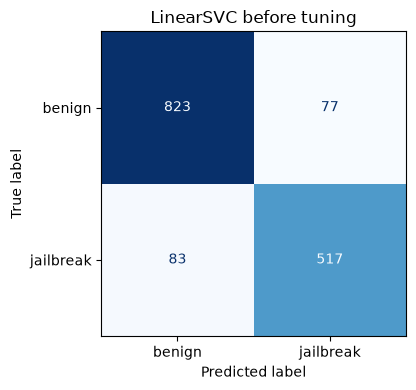

In [6]:
# Check the correct classification, number of false alarms, and number of missed alarms before parameter tuning.
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_base, labels=LABELS, ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("LinearSVC before tuning")

plt.tight_layout()
if SAVE_PLOTS:
    plt.savefig(data_dir.parent.parent / "confusion_matrix_before.png", dpi=150)
plt.show()

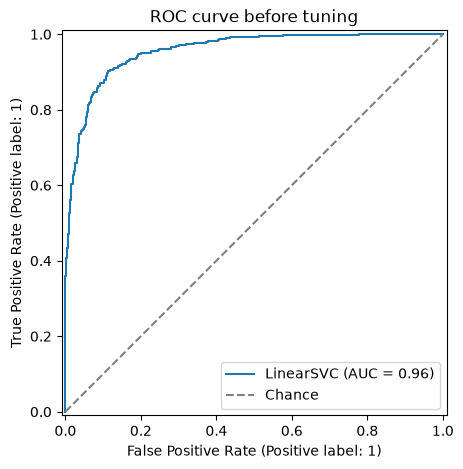

In [7]:
# Plot the ROC curve before parameter tuning. Mark the reference line for random guessing.
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test_binary, scores_base, name="LinearSVC", ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.legend()
plt.title("ROC curve before tuning")

if SAVE_PLOTS:
    plt.savefig(data_dir.parent.parent / "roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## **3 Hyperparameter Selection**

---

### **3.1 Hyperparameters Justification**


| Setting | Component | Starting value | Role |
|---|---|---|---|
| ngram_range | TF-IDF | (1, 1) | Sets the lengths of word sequences the model can use. |
| max_features | TF-IDF | 50,000 | Caps the size of the vocabulary. |
| min_df | TF-IDF | 2 | Drops terms that appear in fewer than this many training prompts. |
| sublinear_tf | TF-IDF | True | Reduces the influence of repeated terms with a log transform. This setting stays fixed. |
| C | LinearSVC | 1.0 | Sets the penalty for margin violations. A higher value reduces regularization. |
| max_iter | LinearSVC | 3,000 | Limits the number of training iterations. This setting stays fixed. |

### **3.2 Tune LinearSVC with GridSearchCV**

---

GridSearch tries **54 combinations**. Each is evaluated on the same five stratified folds using macro F1. Fitting TF-IDF inside the pipeline lets each fold learn its vocabulary and weights from the corresponding training records.

In [8]:
# Create a five-fold division, ensuring each fold has similar proportion of categories.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# The part before the double underscore is name of the Pipeline step, and the part after it is the parameter for that step.
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [30_000, 50_000, 80_000],
    "tfidf__min_df": [1, 2, 5],
    "svm__C": [0.1, 1.0, 10.0]
}

# Search for parameters using the training set, and then fit the optimal configuration using all training samples.
grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=cv, 
    scoring="f1_macro", 
    n_jobs=4, 
    verbose=1, 
    refit=True
)
grid_search.fit(X_train, y_train)

# Evaluate the baseline with the same five folds used in the grid search.
baseline_cv = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=4)

print(f"Baseline CV macro F1: {baseline_cv.mean():.4f}")
print("Best grid parameters:", grid_search.best_params_)
print(f"Best grid CV macro F1: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Baseline CV macro F1: 0.8738
Best grid parameters: {'svm__C': 1.0, 'tfidf__max_features': 50000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Best grid CV macro F1: 0.8851


#### **Effect of C in the LinearSVC Grid**

For each `C`, the plot shows the best validation macro F1 found across the TF-IDF settings tested at that value.

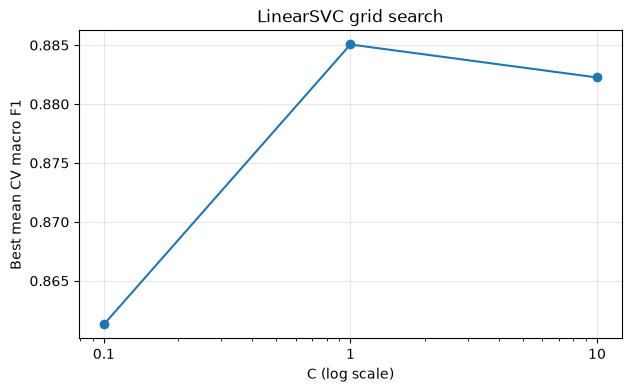

In [9]:
# Group by C value and take the average F1 of the highest validation macro in each group.
cv_results = pd.DataFrame(grid_search.cv_results_)
c_performance = cv_results.groupby("param_svm__C")["mean_test_score"].max()

plt.figure(figsize=(7, 4))
plt.plot(c_performance.index, c_performance.values, marker="o")
plt.xscale("log")
plt.xticks([0.1, 1, 10], ["0.1", "1", "10"])
plt.xlabel("C (log scale)")
plt.ylabel("Best mean CV macro F1")
plt.title("LinearSVC grid search")
plt.grid(alpha=0.3)

if SAVE_PLOTS:
    plt.savefig(data_dir.parent.parent / "c_param_effect.png", dpi=150, bbox_inches="tight")
plt.show()

### **3.3 Evaluate LinearSVC after Tuning**

GridSearchCV refits LinearSVC with the best settings on all 3,500 training prompts. Evaluate it on the same 1,500 test prompts as in Q2.

In [10]:
# Take the LinearSVC trained with the optimal parameters and predict the same test set.
best_linear = grid_search.best_estimator_
y_pred_best_linear = best_linear.predict(X_test)
scores_best_linear = best_linear.decision_function(X_test)

print("LinearSVC after tuning")
print(classification_report(y_test, y_pred_best_linear, labels=LABELS, digits=4))
print(f"ROC AUC: {roc_auc_score(y_test_binary, scores_best_linear):.4f}")

LinearSVC after tuning
              precision    recall  f1-score   support

      benign     0.9152    0.8989    0.9070       900
   jailbreak     0.8523    0.8750    0.8635       600

    accuracy                         0.8893      1500
   macro avg     0.8837    0.8869    0.8852      1500
weighted avg     0.8900    0.8893    0.8896      1500

ROC AUC: 0.9612


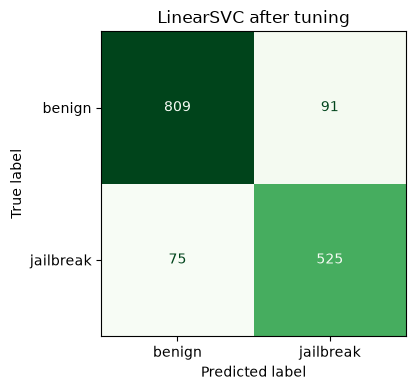

In [11]:
# Check the correct classification, number of false alarms, and number of missed alarms after parameter tuning.
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best_linear, labels=LABELS, ax=ax, cmap="Greens", colorbar=False
)
ax.set_title("LinearSVC after tuning")

plt.tight_layout()
if SAVE_PLOTS:
    plt.savefig(data_dir.parent.parent / "confusion_matrix_after.png", dpi=150)
plt.show()